# 05 · Bottleneck Identification
*EV capacity planning for PowerCharge Utilities · notebook 5 of 8 · Anna Tafri*

Reads: `data/processed/ev_events_clean.csv`, `substations_clean.csv`, `substation_capacity.csv`  
Writes: `data/processed/bottleneck_scores.csv`, `reports/bottleneck_register.csv`, `reports/figures/05_*.png`

### Business question
> Which substations are the real bottlenecks, how confident are we, and *why* is each one at risk?

Notebook 04 ranked substations under one set of assumptions. A planner cannot commit capital on a ranking that might flip if one assumption is wrong. This notebook makes the bottleneck list decision-grade in three ways:

1. **Breach probability.** Run the capacity model across 45 combinations of the uncertain assumptions, and count how often each substation breaches.
2. **Multi-factor risk score.** Combine capacity stress with operational risk factors such as fast-charger exposure, peak-hour exposure, and absolute headroom.
3. **Root cause.** Identify the main driver for each bottleneck, so the fix in Notebook 06 targets the actual problem.


## 0. Setup

In [1]:
import sys
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT_ROOT / "data" / "processed"
REPORTS = PROJECT_ROOT / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from ev_utils import capacity_model

pd.set_option("display.float_format", "{:,.2f}".format)

INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # fixed categorical order
TIER_COLORS = {"Tier 1 - Act": "#d03b3b", "Tier 2 - Plan": "#fab219", "Tier 3 - Monitor": "#2a78d6"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

events = pd.read_csv(PROCESSED / "ev_events_clean.csv", parse_dates=["timestamp"])
subs = pd.read_csv(PROCESSED / "substations_clean.csv")
cap = pd.read_csv(PROCESSED / "substation_capacity.csv", index_col="substation_id")

# Same base assumptions as Notebook 04
CHARGER_KW_SETS = {
    "Low":  {"Type 1": 3.7, "Type 2": 11.0, "DC Fast": 50.0},
    "Base": {"Type 1": 7.4, "Type 2": 22.0, "DC Fast": 50.0},
    "High": {"Type 1": 7.4, "Type 2": 22.0, "DC Fast": 150.0},
}
PLANNING_LIMIT = 0.80
DESIGN_GROWTH = 20   # the 'High' scenario from Notebook 04 is our planning horizon
print(events.shape, subs.shape, cap.shape)

(97, 30) (50, 4) (50, 16)


## 1. Breach probability across 45 assumption combinations
Instead of trusting one base case, we sweep every combination of the three uncertain inputs:

| Input | Values tested |
|---|---|
| Base-load utilisation | 55%, 60%, 65%, 70%, 75% |
| Charger ratings | Low, Base, High |
| Coincidence factor | 0.5, 0.7, 1.0 |

5 × 3 × 3 = 45 scenarios, all at the 20× design growth. A substation's *breach probability* is the share of scenarios in which it passes the 80% planning limit. Every combination is treated as equally likely. This is a simple, transparent alternative to a full Monte Carlo simulation.

In [2]:
GRID_ = list(itertools.product([0.55, 0.60, 0.65, 0.70, 0.75], CHARGER_KW_SETS, [0.5, 0.7, 1.0]))

breach = pd.DataFrame({
    f"bl{bl:.2f}_{kw}_cf{cf}": capacity_model(events, subs, CHARGER_KW_SETS[kw], bl, cf, PLANNING_LIMIT,
                                              growth=DESIGN_GROWTH)["utilisation"] >= PLANNING_LIMIT
    for bl, kw, cf in GRID_
})
breach_prob = breach.mean(axis=1).rename("breach_prob")
print(f"{breach.shape[1]} scenarios evaluated for {breach.shape[0]} substations")
breach_prob.sort_values(ascending=False).head(12).to_frame()

45 scenarios evaluated for 50 substations


,breach_prob
substation_id,
Substation_258,0.96
Substation_560,0.91
Substation_64,0.87
Substation_720,0.82
Substation_999,0.73
Substation_516,0.73
Substation_11_B,0.71
Substation_470,0.71
Substation_301,0.71


## 2. Risk factors
Each factor is chosen because it has a clear physical or operational link to failure, not just because it is available.

In [3]:
KW = "electricity_consumption_kwh"
ev = events.assign(connected_kw=events["number_of_evs"] * events["charger_type"].map(CHARGER_KW_SETS["Base"]))
g = ev.groupby("substation_id")

factors = pd.DataFrame({
    # 1. Capacity stress: how little growth it can take (inverse of the breaking multiple)
    "capacity_stress": 1 / cap["breaking_multiple"],
    # 2. Robustness: breaches across the assumption sweep
    "breach_prob": breach_prob,
    # 3. Fast-charger exposure: share of connected kW on DC fast chargers (most sensitive to rating upgrades)
    "fast_charger_share": g.apply(lambda x: x.loc[x["charger_type"] == "DC Fast", "connected_kw"].sum() / x["connected_kw"].sum()),
    # 4. Peak exposure: share of the substation's EV energy drawn in the 17:00-21:00 window
    "peak_exposure": g.apply(lambda x: x.loc[x["is_peak_hour"], KW].sum() / x[KW].sum()),
    # 5. Thin margin: small absolute headroom (MW) leaves no room for error, even if the % looks fine
    "thin_margin": 1 / cap["headroom_mw"],
    # 6. Feeder length: long feeders suffer voltage drop (relative signal only, see DQ-05)
    "feeder_length": g["station_to_sub_km"].mean(),
}).reindex(cap.index).fillna(0)

factors.describe().T[["mean", "min", "max"]]

,mean,min,max
capacity_stress,0.03,0.00,0.11
breach_prob,0.32,0.00,0.96
fast_charger_share,0.44,0.00,1.00
peak_exposure,0.22,0.00,1.00
thin_margin,0.18,0.07,0.68
feeder_length,"2,877.21",0.00,"6,217.65"


### Weighting
Weights reflect how directly each factor causes a capacity failure. They are an explicit judgement, and section 5 tests whether the ranking survives other weightings.

| Factor | Weight | Rationale |
|---|---|---|
| Capacity stress | 35% | The direct measure of how soon the planning limit is reached |
| Breach probability | 25% | Rewards risk that holds up under uncertainty |
| Fast-charger exposure | 15% | Fast chargers drive the biggest upside risk (Notebook 04 sensitivity) |
| Peak exposure | 10% | Load in the 17:00–21:00 window coincides with the network peak |
| Thin margin | 10% | Small absolute headroom leaves little operational buffer |
| Feeder length | 5% | Physically important, but the coordinates are synthetic, so low weight |

Each factor is min-max scaled to 0–1 so the weights mean what they say.

In [4]:
WEIGHTS = {"capacity_stress": 0.35, "breach_prob": 0.25, "fast_charger_share": 0.15,
           "peak_exposure": 0.10, "thin_margin": 0.10, "feeder_length": 0.05}
assert abs(sum(WEIGHTS.values()) - 1) < 1e-9

scaled = (factors - factors.min()) / (factors.max() - factors.min())

def risk_score(weights):
    return (scaled[list(weights)] * pd.Series(weights)).sum(axis=1) * 100

contrib = scaled[list(WEIGHTS)] * pd.Series(WEIGHTS) * 100      # points each factor adds
scores = factors.assign(risk_score=contrib.sum(axis=1),
                        primary_driver=contrib.idxmax(axis=1))
scores["rank"] = scores["risk_score"].rank(ascending=False, method="min").astype(int)
scores.sort_values("risk_score", ascending=False).head(10)

,capacity_stress,breach_prob,fast_charger_share,peak_exposure,thin_margin,feeder_length,risk_score,primary_driver,rank
substation_id,,,,,,,,,
Substation_258,0.11,0.96,1.00,0.00,0.34,"3,062.42",81.83,capacity_stress,1
Substation_720,0.07,0.82,1.00,1.00,0.34,"6,217.65",77.90,capacity_stress,2
Substation_560,0.09,0.91,0.95,0.00,0.11,"2,231.01",70.51,capacity_stress,3
Substation_64,0.07,0.87,1.00,0.00,0.28,"2,907.72",67.05,capacity_stress,4
Substation_516,0.06,0.73,1.00,0.64,0.08,"2,638.23",61.21,breach_prob,5
Substation_816,0.05,0.69,1.00,1.00,0.11,"1,955.80",60.57,breach_prob,6
Substation_301,0.09,0.71,0.00,0.00,0.37,"2,588.18",54.28,capacity_stress,7
Substation_999,0.06,0.73,0.75,0.00,0.16,"3,848.28",54.12,breach_prob,8
Substation_470,0.06,0.71,0.72,0.00,0.14,"3,190.90",51.53,breach_prob,9


## 3. Tiering: from a score to a decision
A score ranks substations, but executives need categories that map to actions. The tiers use breach probability, because "how sure are we that this breaks at 20× growth?" is the question a capital committee asks.

| Tier | Rule | Action |
|---|---|---|
| Tier 1 – Act | Breaches in ≥ 70% of scenarios | Include in the upgrade programme (Notebook 06) |
| Tier 2 – Plan | Breaches in 40–70% of scenarios | Engineering study, then re-assess with real load data |
| Tier 3 – Monitor | Breaches in < 40% of scenarios | Annual monitoring through utilisation dashboards |

In [5]:
scores["tier"] = np.select(
    [scores["breach_prob"] >= 0.70, scores["breach_prob"] >= 0.40],
    ["Tier 1 - Act", "Tier 2 - Plan"], "Tier 3 - Monitor")

tier_summary = (scores.join(cap[["capacity_mw", "breaking_multiple"]])
                .groupby("tier")
                .agg(substations=("risk_score", "size"), avg_score=("risk_score", "mean"),
                     median_capacity_mw=("capacity_mw", "median"),
                     median_breaking_multiple=("breaking_multiple", "median")))
tier_summary

,substations,avg_score,median_capacity_mw,median_breaking_multiple
tier,,,,
Tier 1 - Act,9,63.22,43.00,15.00
Tier 2 - Plan,10,46.35,50.00,27.07
Tier 3 - Monitor,31,16.69,59.00,69.17


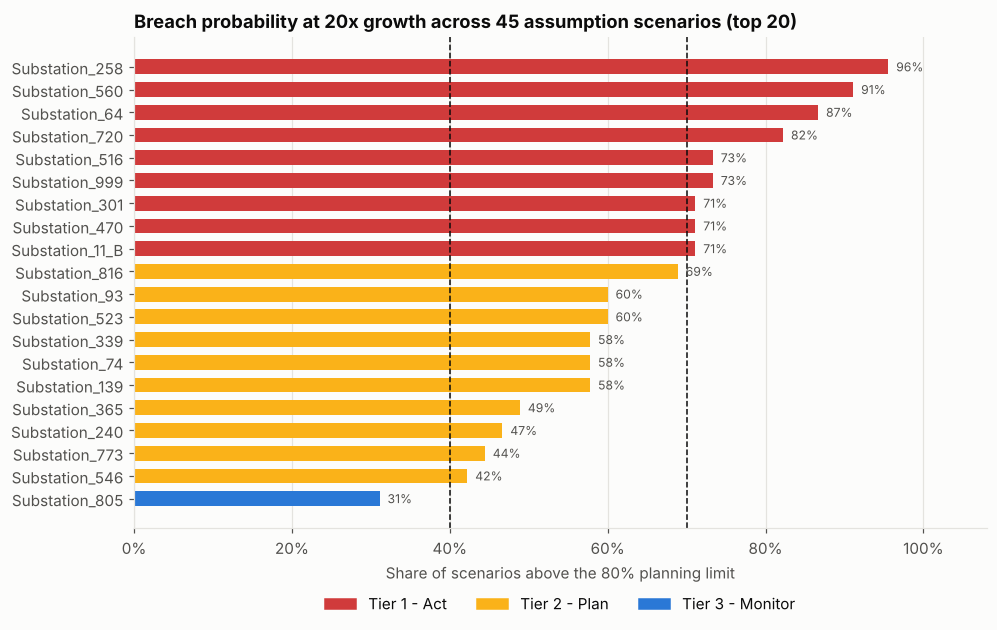

In [6]:
top = scores.sort_values(["breach_prob", "risk_score"], ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(top.index, top["breach_prob"], color=[TIER_COLORS[t] for t in top["tier"]], height=0.65)
for x in (0.4, 0.7):
    ax.axvline(x, color=INK, linewidth=1, linestyle="--")
for yi, v in enumerate(top["breach_prob"]):
    ax.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=8, color=INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set(title="Breach probability at 20x growth across 45 assumption scenarios (top 20)",
       xlabel="Share of scenarios above the 80% planning limit", xlim=(0, 1.08))
ax.legend(handles=[Patch(color=c, label=l) for l, c in TIER_COLORS.items()],
          loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=3)
ax.grid(axis="y", visible=False)
save(fig, "05_01_breach_probability"); plt.show()

## 4. Why is each substation at risk? (score decomposition)

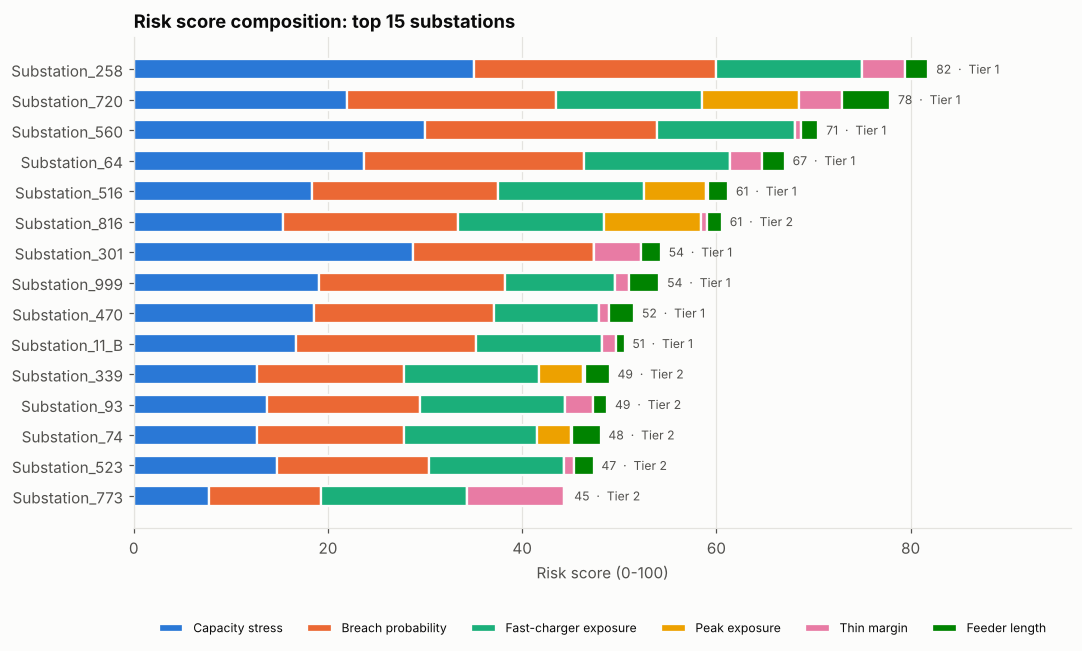

,Tier 1-2 substations
primary_driver,
Breach probability,11
Capacity stress,5
Fast-charger exposure,3


In [7]:
LABELS = {"capacity_stress": "Capacity stress", "breach_prob": "Breach probability",
          "fast_charger_share": "Fast-charger exposure", "peak_exposure": "Peak exposure",
          "thin_margin": "Thin margin", "feeder_length": "Feeder length"}
top15 = scores.nlargest(15, "risk_score").index[::-1]
fig, ax = plt.subplots(figsize=(11, 5.8))
left = np.zeros(len(top15))
for color, f in zip(SERIES, WEIGHTS):
    vals = contrib.loc[top15, f].values
    ax.barh(top15, vals, left=left, color=color, height=0.65, edgecolor=SURFACE, linewidth=1.5, label=LABELS[f])
    left += vals
for yi, (sid, total) in enumerate(zip(top15, left)):
    ax.text(total + 0.8, yi, f"{total:.0f}  ·  {scores.loc[sid, 'tier'].split(' - ')[0]}", va="center", fontsize=8, color=INK_2)
ax.set(title="Risk score composition: top 15 substations", xlabel="Risk score (0-100)", xlim=(0, left.max() * 1.18))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.24), ncol=6, fontsize=8)
ax.grid(axis="y", visible=False)
save(fig, "05_02_score_composition"); plt.show()

scores.loc[scores["tier"] != "Tier 3 - Monitor", "primary_driver"].map(LABELS).value_counts().to_frame("Tier 1-2 substations")

**Reading it**
- For 16 of the 19 Tier 1–2 substations, capacity stress or breach probability is the main driver. These are structural problems: too much EV load for the size of the substation.
- For 3 Tier 2 substations (Substation_773, _365, _240), fast-charger exposure is the main driver. Their risk comes from *how* vehicles charge rather than how many there are. Managed (smart) charging or on-site battery buffering can be cheaper than a transformer upgrade for these.
- Peak exposure is never the *main* driver. However, Substation_720 and Substation_816 draw all of their EV energy in the 17:00–21:00 window, so time-of-use tariffs are a realistic lever there.

This driver split is the bridge to Notebook 06: different root causes call for different, and sometimes cheaper, fixes.

## 5. Is the ranking robust to the weights?
If a reasonable person chose different weights, would the bottleneck list change? We test four alternative weightings against the base.

In [8]:
ALT_WEIGHTS = {
    "Equal weights": {f: 1 / 6 for f in WEIGHTS},
    "Capacity only": {"capacity_stress": 0.6, "breach_prob": 0.4},
    "Operational focus": {"capacity_stress": 0.2, "breach_prob": 0.2, "fast_charger_share": 0.25,
                          "peak_exposure": 0.2, "thin_margin": 0.1, "feeder_length": 0.05},
    "No feeder length": {"capacity_stress": 0.37, "breach_prob": 0.26, "fast_charger_share": 0.16,
                         "peak_exposure": 0.11, "thin_margin": 0.10},
}
base_top10 = set(scores.nlargest(10, "risk_score").index)
robust = pd.DataFrame({
    name: {"rank correlation vs base": scores["risk_score"].corr(risk_score(w), method="spearman"),
           "top-10 overlap": len(base_top10 & set(risk_score(w).nlargest(10).index)) / 10}
    for name, w in ALT_WEIGHTS.items()
}).T
robust.style.format({"rank correlation vs base": "{:.2f}", "top-10 overlap": "{:.0%}"})

,rank correlation vs base,top-10 overlap
Equal weights,0.97,70%
Capacity only,0.95,100%
Operational focus,0.96,60%
No feeder length,1.00,100%


In [9]:
# Which substations stay in the top 10 under every weighting?
always_top10 = set(base_top10)
for w in ALT_WEIGHTS.values():
    always_top10 &= set(risk_score(w).nlargest(10).index)
print(f"In the top 10 under all 5 weightings ({len(always_top10)}):", sorted(always_top10))

In the top 10 under all 5 weightings (6): ['Substation_258', 'Substation_516', 'Substation_560', 'Substation_64', 'Substation_720', 'Substation_816']


**Reading it:** rank correlation stays at 0.95 or above under every alternative, and the top 10 overlaps by 60–100%. Six substations (258, 720, 560, 64, 516, 816) make the top 10 under *every* weighting. They are the most defensible priorities in the network.

## 6. The risk frontier
This chart shows the whole network on one page. Each substation is plotted by capacity and EV peak load. The dashed lines mark where a substation would breach at 10× and 20× growth, so anything above a line breaches before that growth level.

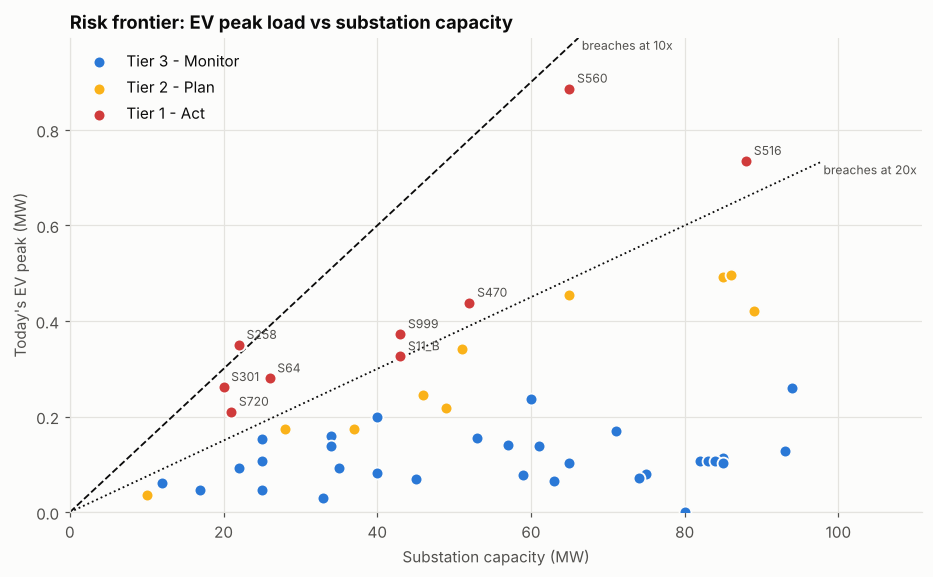

In [10]:
d = cap.join(scores[["tier", "risk_score"]])
fig, ax = plt.subplots(figsize=(10, 5.6))
x_max, y_max = d["capacity_mw"].max() * 1.18, d["ev_peak_mw"].max() * 1.12
slope_base = PLANNING_LIMIT - 0.65
for growth, ls in [(10, "--"), (20, ":")]:
    # Breach line: EV peak x growth = (planning limit - base load) x capacity
    x_end = min(x_max * 0.88, y_max * growth / slope_base)
    xs = np.linspace(0, x_end, 100)
    ax.plot(xs, slope_base * xs / growth, color=INK, linestyle=ls, linewidth=1.2)
    ax.text(x_end, slope_base * x_end / growth, f" breaches at {growth}x", fontsize=8, color=INK_2, va="top")
for tier, color in reversed(list(TIER_COLORS.items())):
    sub = d[d["tier"] == tier]
    ax.scatter(sub["capacity_mw"], sub["ev_peak_mw"], s=60, color=color, edgecolor=SURFACE, linewidth=1.2, label=tier, zorder=3)
for sid, r in d[d["tier"] == "Tier 1 - Act"].iterrows():
    ax.annotate(sid.replace("Substation_", "S"), (r["capacity_mw"], r["ev_peak_mw"]), xytext=(5, 4),
                textcoords="offset points", fontsize=8, color=INK_2)
ax.set(title="Risk frontier: EV peak load vs substation capacity", xlabel="Substation capacity (MW)",
       ylabel="Today's EV peak (MW)", xlim=(0, x_max), ylim=(0, y_max))
ax.legend(loc="upper left")
save(fig, "05_03_risk_frontier"); plt.show()

**Reading it**
- All nine Tier 1 substations sit above the 20× line (Substation_11_B sits right on it). Substation_258 is almost on the 10× line. Tier 2 substations cluster just below the 20× line, so a modest change in assumptions pushes them over. They carry more EV load than their size can absorb.
- Notice that bottlenecks are not only small substations. Substation_560 (65 MW) and Substation_516 (88 MW) are large, but they carry a lot of EV load. That is why the analysis has to look at load *relative to* capacity rather than capacity alone.

## 7. What do the bottlenecks have in common?

In [11]:
site = (events.groupby("substation_id")
        .agg(events=("timestamp", "size"),
             rural_share=("geographical_area", lambda s: (s == "Rural").mean()),
             commercial_share=("customer_type", lambda s: (s == "Commercial").mean()),
             daily_habit_share=("charging_habit", lambda s: (s == "Daily").mean()))
        .reindex(cap.index).fillna(0))
profile = (cap[["capacity_mw", "ev_peak_mw"]].join(site).join(factors[["fast_charger_share", "peak_exposure"]])
           .join(scores["tier"]).groupby("tier").mean())
profile.T

tier,Tier 1 - Act,Tier 2 - Plan,Tier 3 - Monitor
capacity_mw,42.22,54.60,55.19
ev_peak_mw,0.43,0.31,0.11
events,2.22,2.20,1.77
rural_share,0.37,0.57,0.45
commercial_share,0.31,0.48,0.37
daily_habit_share,0.31,0.53,0.34
fast_charger_share,0.81,0.93,0.17
peak_exposure,0.18,0.22,0.23


**Reading it**
- Fast chargers are the common thread. On average, 81% of Tier 1 and 93% of Tier 2 connected EV power sits on DC fast chargers, compared with 17% in Tier 3. This is the single clearest difference between bottlenecks and healthy substations.
- Tier 1 substations carry ~4× the EV peak of Tier 3 (0.43 vs 0.11 MW) on smaller substations (42 vs 55 MW on average).
- Peak exposure, rural share, and customer mix do not separate the tiers clearly. Risk is about charging technology and load relative to size, not *who* the customers are. That matches the EDA finding that segments do not differ in energy per event.

Why it matters: PowerCharge's DC fast-charger connection policy is a lever just as important as transformer upgrades. New DC fast connections at Tier 1–2 substations should trigger a capacity review.

## 8. Bottleneck register
The deliverable for the engineering team: one row per at-risk substation, with its evidence, main driver, and suggested type of intervention.

In [12]:
ACTION = {
    "capacity_stress": "Capacity reinforcement (transformer / feeder upgrade)",
    "breach_prob": "Capacity reinforcement (transformer / feeder upgrade)",
    "thin_margin": "Capacity reinforcement (transformer / feeder upgrade)",
    "fast_charger_share": "Managed charging or battery buffer at DC fast sites",
    "peak_exposure": "Time-of-use tariff / demand response",
    "feeder_length": "Voltage study, then feeder reinforcement",
}
register = (scores.join(cap[["capacity_mw", "ev_peak_mw", "utilisation", "util_20x", "breaking_multiple", "sub_lat", "sub_lon"]])
            .assign(primary_driver_label=lambda t: t["primary_driver"].map(LABELS),
                    suggested_action=lambda t: t["primary_driver"].map(ACTION))
            .sort_values(["tier", "risk_score"], ascending=[True, False]))
cols = ["tier", "rank", "risk_score", "breach_prob", "capacity_mw", "ev_peak_mw", "util_20x",
        "breaking_multiple", "primary_driver_label", "suggested_action"]

register.to_csv(PROCESSED / "bottleneck_scores.csv")
register.loc[register["tier"] != "Tier 3 - Monitor", cols].to_csv(REPORTS / "bottleneck_register.csv")
register.loc[register["tier"] != "Tier 3 - Monitor", cols]

,tier,rank,risk_score,breach_prob,capacity_mw,ev_peak_mw,util_20x,breaking_multiple,primary_driver_label,suggested_action
substation_id,,,,,,,,,,
Substation_258,Tier 1 - Act,1,81.83,0.96,22,0.35,0.97,9.43,Capacity stress,Capacity reinforcement (transformer / feeder u...
Substation_720,Tier 1 - Act,2,77.90,0.82,21,0.21,0.85,15.00,Capacity stress,Capacity reinforcement (transformer / feeder u...
Substation_560,Tier 1 - Act,3,70.51,0.91,65,0.89,0.92,11.00,Capacity stress,Capacity reinforcement (transformer / feeder u...
Substation_64,Tier 1 - Act,4,67.05,0.87,26,0.28,0.87,13.93,Capacity stress,Capacity reinforcement (transformer / feeder u...
Substation_516,Tier 1 - Act,5,61.21,0.73,88,0.73,0.82,17.96,Breach probability,Capacity reinforcement (transformer / feeder u...
Substation_301,Tier 1 - Act,7,54.28,0.71,20,0.26,0.91,11.46,Capacity stress,Capacity reinforcement (transformer / feeder u...
Substation_999,Tier 1 - Act,8,54.12,0.73,43,0.37,0.82,17.32,Breach probability,Capacity reinforcement (transformer / feeder u...
Substation_470,Tier 1 - Act,9,51.53,0.71,52,0.44,0.82,17.80,Breach probability,Capacity reinforcement (transformer / feeder u...
Substation_11_B,Tier 1 - Act,10,50.54,0.71,43,0.33,0.80,19.77,Breach probability,Capacity reinforcement (transformer / feeder u...


## 9. Summary

| Question | Answer |
|---|---|
| How many bottlenecks? | 9 Tier 1 (act) substations breach in ≥ 70% of the 45 assumption scenarios at 20× growth. 10 Tier 2 (plan) breach in 40–70%. |
| How confident are we? | High. Rank correlation is ≥ 0.95 under every alternative weighting, and 6 substations (258, 720, 560, 64, 516, 816) stay in the top 10 under all five weightings. |
| Why are they at risk? | Mostly structural capacity stress. The common thread is DC fast chargers: 81–93% of connected EV power at Tier 1–2 sites, compared with 17% elsewhere. |
| What's the deliverable? | `reports/bottleneck_register.csv`: tier, evidence, driver, and suggested action for each at-risk substation |

**Next:** `06_network_optimization.ipynb`: price the intervention options (reinforcement, managed charging, battery buffers, tariffs), then use optimisation to choose the lowest-cost portfolio that keeps every substation within its planning limit at 20× growth, under a budget constraint.